# Ames Housing Veri Seti - Keşifsel Veri Analizi 
Bu not defteri, konut özelliklerinden satış fiyatı (SalePrice) tahmini yapmak amacıyla verinin yüklenmesi, temizlenmesi ve görselleştirilmesi adımlarını içermektedir.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Grafikler için genel tema ayarı
sns.set_theme(style="whitegrid")

# Veri setini yükleme
df = pd.read_csv('train.csv')
print(f"Başlangıç veri seti boyutu: {df.shape}")

Başlangıç veri seti boyutu: (1460, 81)


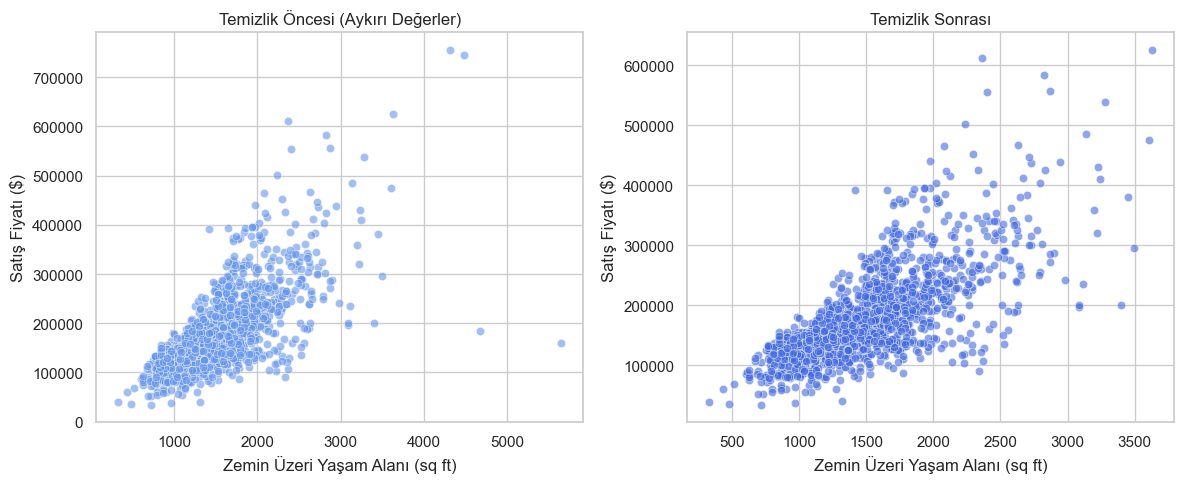

Aykırı değerler temizlendikten sonra boyut: (1456, 81)


In [2]:
# Aykırı Değer (Outlier) Temizliği ve Yaşam Alanı Analizi
plt.figure(figsize=(12, 5))

# Temizlik Öncesi
plt.subplot(1, 2, 1)
sns.scatterplot(x=df['GrLivArea'], y=df['SalePrice'], alpha=0.6, color='cornflowerblue')
plt.title("Temizlik Öncesi (Aykırı Değerler)")
plt.xlabel("Zemin Üzeri Yaşam Alanı (sq ft)")
plt.ylabel("Satış Fiyatı ($)")

# 4000 sq ft üzerindeki aykırı değerleri çıkarma
df_cleaned = df.drop(df[(df['GrLivArea'] > 4000)].index)

# Temizlik Sonrası
plt.subplot(1, 2, 2)
sns.scatterplot(x=df_cleaned['GrLivArea'], y=df_cleaned['SalePrice'], alpha=0.6, color='royalblue')
plt.title("Temizlik Sonrası")
plt.xlabel("Zemin Üzeri Yaşam Alanı (sq ft)")
plt.ylabel("Satış Fiyatı ($)")

plt.tight_layout()
plt.show()

print(f"Aykırı değerler temizlendikten sonra boyut: {df_cleaned.shape}")

**Analiz:** Literatürdeki önerilere (De Cock, 2011) uygun olarak, 4.000 metrekareden büyük zemin üstü yaşam alanına (`GrLivArea`) sahip evler istisnai (outlier) kabul edilmiştir. Temizlik öncesi grafikte sağ alt köşede yer alan, çok büyük olmasına rağmen düşük fiyata satılmış evler modelin öğrenme eğrisini bozacağı için veri setinden çıkarılmıştır.

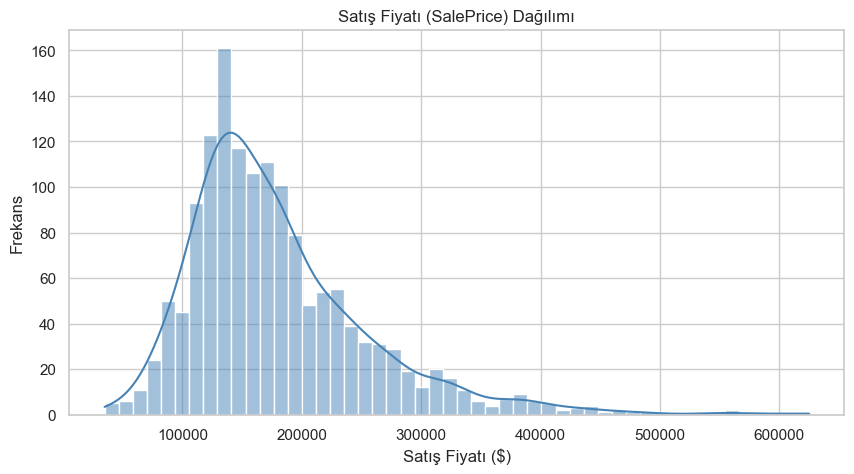

In [3]:
# Hedef Değişken (SalePrice) Dağılımı
plt.figure(figsize=(10, 5))
sns.histplot(df_cleaned['SalePrice'], kde=True, bins=50, color='steelblue')
plt.title('Satış Fiyatı (SalePrice) Dağılımı')
plt.xlabel('Satış Fiyatı ($)')
plt.ylabel('Frekans')
plt.show()

**Analiz:** Satış fiyatlarının dağılımı sağa çarpık (right-skewed) bir yapı göstermektedir. Evlerin büyük bir çoğunluğu 100.000$ ile 200.000$ bandında toplanırken, 400.000$ üzerindeki lüks evlerin sayısı oldukça azdır. Regresyon modellerinin hataları minimize edebilmesi için ileriki modelleme aşamalarında hedef değişkene logaritmik dönüşüm (Log Transform) uygulanması performansı artırabilir.

C:\Users\Onur Fidan\AppData\Local\Temp\ipykernel_12844\3418726417.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='OverallQual', y='SalePrice', data=df_cleaned, palette='viridis')


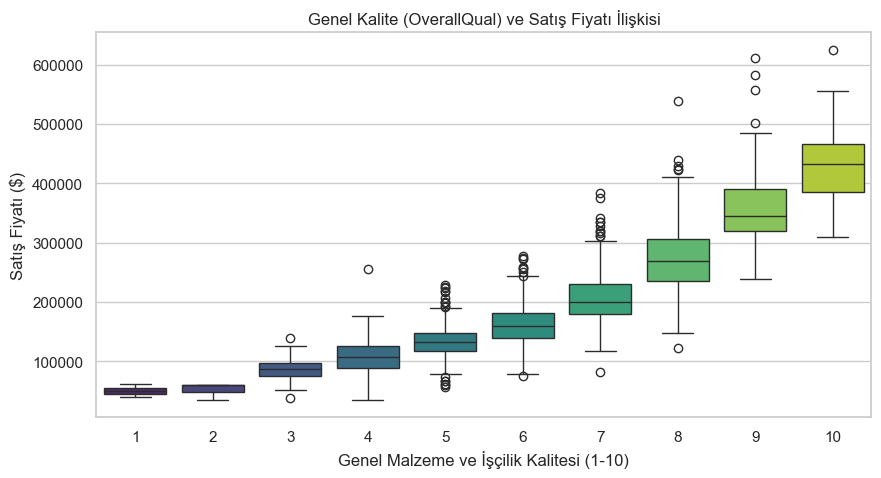

In [4]:
# Genel Kalite (OverallQual) Analizi
plt.figure(figsize=(10, 5))
sns.boxplot(x='OverallQual', y='SalePrice', data=df_cleaned, palette='viridis')
plt.title('Genel Kalite (OverallQual) ve Satış Fiyatı İlişkisi')
plt.xlabel('Genel Malzeme ve İşçilik Kalitesi (1-10)')
plt.ylabel('Satış Fiyatı ($)')
plt.show()

**Analiz:** Evin genel kalitesi (1'den 10'a kadar puanlanmış) ile satış fiyatı arasında çok güçlü ve eksponansiyel bir ilişki bulunmaktadır. Kalite puanı arttıkça fiyatların varyansı (kutu boyutu) genişlemektedir; bu da yüksek kaliteli evlerde fiyatı etkileyen başka lüks donanımların da devreye girdiğini göstermektedir.

C:\Users\Onur Fidan\AppData\Local\Temp\ipykernel_12844\569591496.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Neighborhood', y='SalePrice', data=df_cleaned, order=order, palette='Set2')


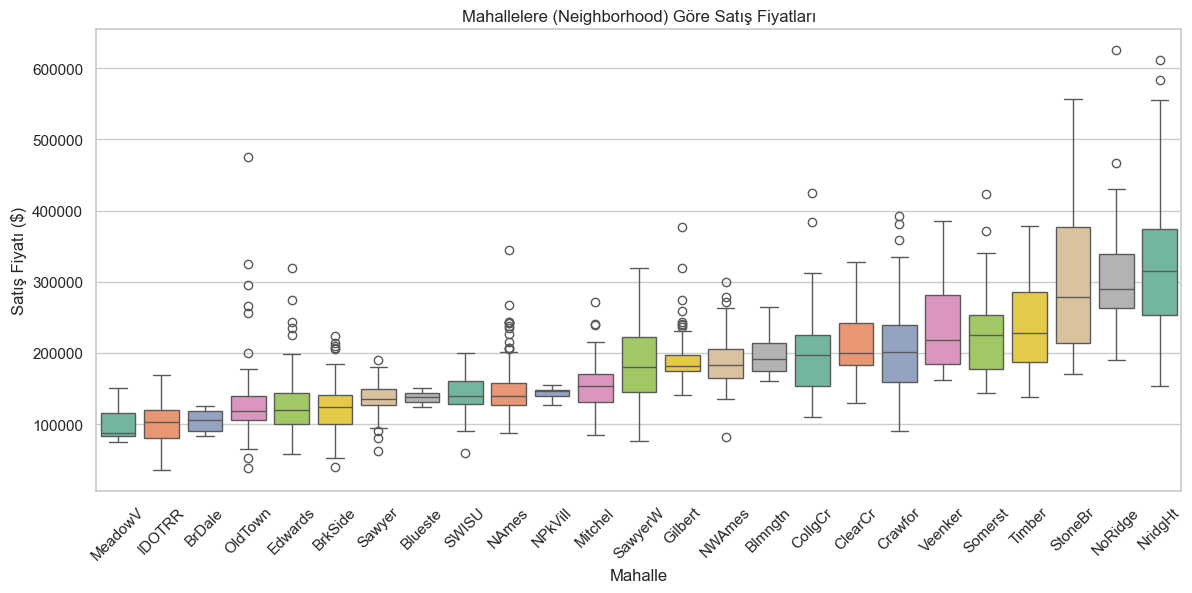

In [5]:
# Mahalle (Neighborhood) Analizi
plt.figure(figsize=(14, 6))
# Mahalleleri medyan fiyata göre küçükten büyüğe sıralama
order = df_cleaned.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x='Neighborhood', y='SalePrice', data=df_cleaned, order=order, palette='Set2')
plt.title('Mahallelere (Neighborhood) Göre Satış Fiyatları')
plt.xticks(rotation=45)
plt.xlabel('Mahalle')
plt.ylabel('Satış Fiyatı ($)')
plt.show()

**Analiz:** Gayrimenkul değerlemesinde lokasyonun önemi bu grafikte netleşmektedir. *MeadowV* ve *IDOTRR* gibi mahalleler dar bir fiyat aralığında bütçe dostu seçenekler sunarken, *NoRidge* ve *NridgHt* mahalleleri çok daha yüksek medyan fiyatlara ve geniş bir lüks segmentine sahiptir. Model, mahalle değişkeninden önemli ağırlıklar öğrenecektir.

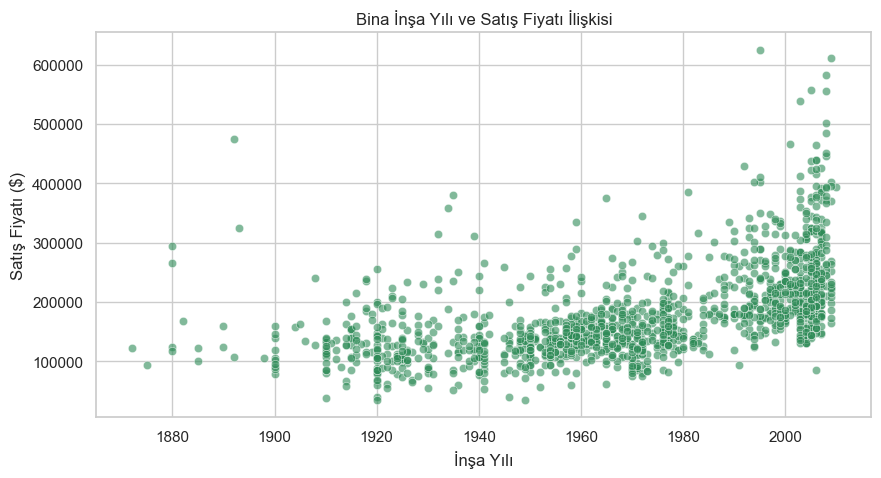

In [6]:
# Bina Yaşı (YearBuilt) Analizi
plt.figure(figsize=(10, 5))
sns.scatterplot(x='YearBuilt', y='SalePrice', data=df_cleaned, alpha=0.6, color='seagreen')
plt.title('Bina İnşa Yılı ve Satış Fiyatı İlişkisi')
plt.xlabel('İnşa Yılı')
plt.ylabel('Satış Fiyatı ($)')
plt.show()

**Analiz:** Genel eğilim, evin yapım yılı yenilendikçe satış fiyatının arttığı yönündedir (özellikle 1980 sonrası ivmelenme). Ancak 1880-1920 yılları arasında inşa edilmiş bazı tarihi evlerin, restorasyon veya tarihi değer faktörleriyle 1950'lerde yapılmış evlerden daha yüksek fiyatlara satılabildiği görülmektedir.

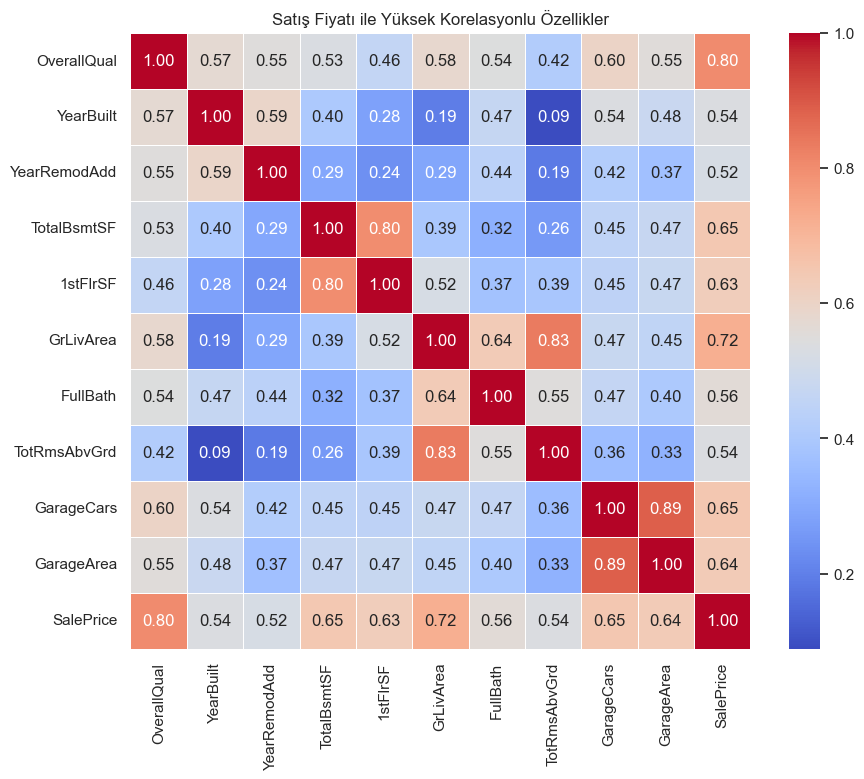

In [7]:
# Korelasyon Matrisi ve Isı Haritası
# Yalnızca sayısal değişkenleri seçme
numeric_df = df_cleaned.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# SalePrice ile korelasyonu 0.5'ten büyük olan özellikleri filtreleme
top_corr_features = corr_matrix.index[abs(corr_matrix["SalePrice"]) > 0.5]

plt.figure(figsize=(10, 8))
sns.heatmap(df_cleaned[top_corr_features].corr(), annot=True, cmap="coolwarm", linewidths=.5, fmt=".2f")
plt.title("Satış Fiyatı ile Yüksek Korelasyonlu Özellikler")
plt.show()

**Analiz:** Hedef değişkenimiz olan `SalePrice` ile en güçlü doğrusal ilişkiye sahip ilk üç değişken sırasıyla: Genel Kalite (`OverallQual` - 0.80), Zemin Üzeri Yaşam Alanı (`GrLivArea` - 0.72) ve Garaj Araç Kapasitesidir (`GarageCars` - 0.65). Ayrıca garaj alanı ile araç kapasitesi (0.89), 1. kat alanı ile toplam bodrum alanı (0.80) arasında yüksek iç korelasyon (multicollinearity) gözlemlenmiştir. İlerleyen aşamalarda bu değişkenlerden bazıları model sağlığı için düşürülebilir.